<a href="https://colab.research.google.com/github/mooygheave-glitch/soil-moisture-decision-tree/blob/main/soil-moisture-decision-tree-final/notebooks/Kel_7_decision_tree_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Decision Tree: Soil Moisture + Measurement Hour

Notebook baseline for the UTS project. Features: `soil_moisture_adc` and `jam_pengukuran`. Target: `label`.

**Important:** dry data were collected at night and wet data around midday on a different date. This creates a confounding relationship between measurement hour and label. The model may exploit time as a shortcut. Results are a baseline demonstration, not proof of generalization.


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

DATA_DIR = Path("../content/soil-moisture-decision-tree-final/data/raw") # For Colab, change to the extracted project data/raw path


In [3]:
import zipfile
from pathlib import Path

zip_path = Path("/content/soil-moisture-decision-tree-final.zip")
extract_path = Path("/content")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Ekstraksi selesai.")
print(list(extract_path.iterdir()))

Ekstraksi selesai.
[PosixPath('/content/.config'), PosixPath('/content/soil-moisture-decision-tree-final.zip'), PosixPath('/content/soil-moisture-decision-tree-final'), PosixPath('/content/sample_data')]


In [4]:
from pathlib import Path

matches = list(
    Path("/content").glob(
        "soil-moisture-decision-tree-final/data/raw"
    )
)

print(matches)

[PosixPath('/content/soil-moisture-decision-tree-final/data/raw')]


In [6]:
files = ["uji_kering_1.csv", "uji_kering_2.csv", "uji_basah_1.csv", "uji_basah_2.csv"]
parts = []
for filename in files:
    part = pd.read_csv(DATA_DIR / filename)
    part["session"] = Path(filename).stem
    parts.append(part)
df = pd.concat(parts, ignore_index=True)
df.head()


,recorded_at,elapsed_ms,soil_moisture_adc,label,session
0,2026-10-13T20:22:03,10000,3652,kering,uji_kering_1
1,2026-10-13T20:22:13,20000,3624,kering,uji_kering_1
2,2026-10-13T20:22:23,30000,3620,kering,uji_kering_1
3,2026-10-13T20:22:33,40000,3598,kering,uji_kering_1
4,2026-10-13T20:22:43,50000,3570,kering,uji_kering_1


In [7]:
print("Shape:", df.shape)
print("\nMissing values:\n", df.isna().sum())
print("\nLabels:\n", df["label"].value_counts())
print("\nLabels per session:\n", pd.crosstab(df["session"], df["label"]))

df["recorded_at"] = pd.to_datetime(df["recorded_at"], errors="coerce")
df["soil_moisture_adc"] = pd.to_numeric(df["soil_moisture_adc"], errors="coerce")
df["label"] = df["label"].astype(str).str.strip().str.lower()
df["jam_pengukuran"] = df["recorded_at"].dt.hour
df = df.dropna(subset=["soil_moisture_adc", "jam_pengukuran", "label"])
df = df[df["label"].isin(["kering", "basah"])].copy()

print("\nJam pengukuran per label:\n", pd.crosstab(df["jam_pengukuran"], df["label"]))
display(df.groupby("label")["soil_moisture_adc"].agg(["count","mean","median","std","min","max"]).round(2))


Shape: (177, 5)

Missing values:
 recorded_at          0
elapsed_ms           0
soil_moisture_adc    0
label                0
session              0
dtype: int64

Labels:
 label
kering    125
basah      52
Name: count, dtype: int64

Labels per session:
 label         basah  kering
session                    
uji_basah_1      25       0
uji_basah_2      27       0
uji_kering_1      0      55
uji_kering_2      0      70

Jam pengukuran per label:
 label           basah  kering
jam_pengukuran               
12                 21       0
13                 31       0
20                  0      38
21                  0      87


,count,mean,median,std,min,max
label,,,,,,
basah,52,3298.58,3299.0,14.9,3250,3326
kering,125,3606.56,3601.0,88.9,3505,4002


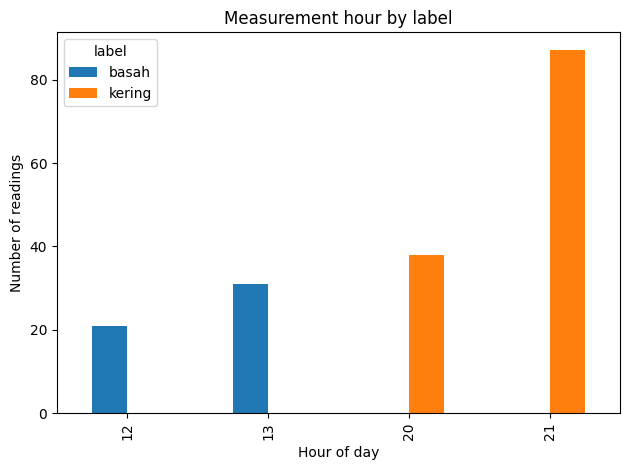

In [8]:
pd.crosstab(df["jam_pengukuran"], df["label"]).plot(kind="bar")
plt.title("Measurement hour by label")
plt.xlabel("Hour of day"); plt.ylabel("Number of readings")
plt.tight_layout(); plt.show()


Training rows: 132 | Test rows: 45
Accuracy: 1.0
              precision    recall  f1-score   support

       basah       1.00      1.00      1.00        13
      kering       1.00      1.00      1.00        32

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



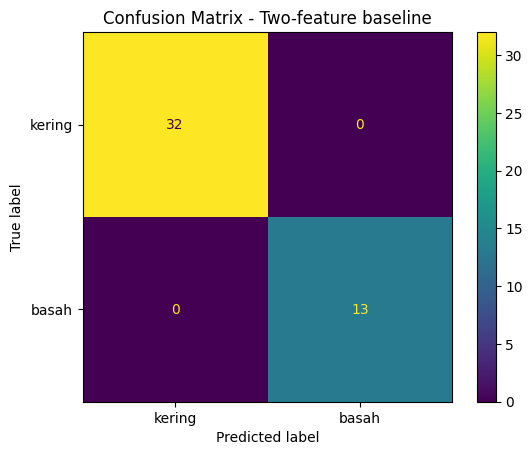

In [9]:
# Features: raw ADC + hour of day. Target: dry/wet label.
X = df[["soil_moisture_adc", "jam_pengukuran"]]
y = df["label"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
model = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, zero_division=0))
labels = ["kering", "basah"]
cm = confusion_matrix(y_test, y_pred, labels=labels)
ConfusionMatrixDisplay(cm, display_labels=labels).plot()
plt.title("Confusion Matrix - Two-feature baseline")
plt.show()


## Decision Tree visualization

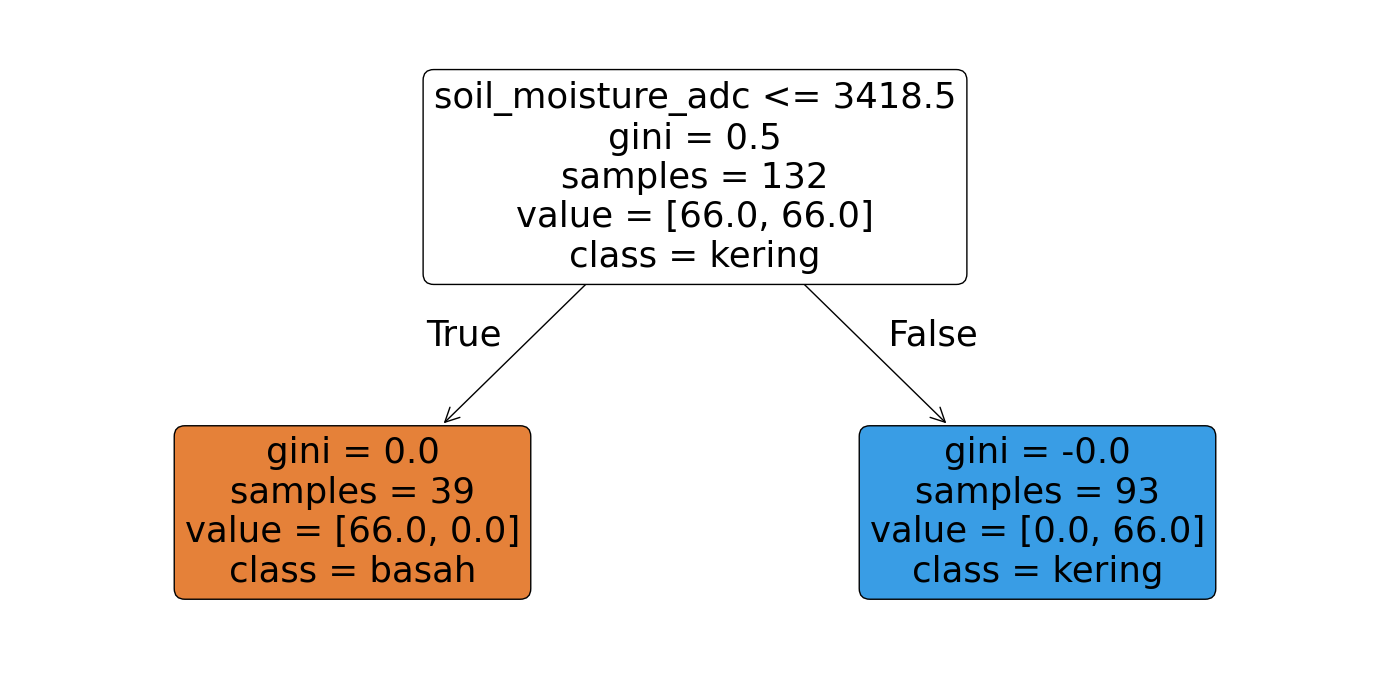

In [10]:
plt.figure(figsize=(14, 7))
plot_tree(model, feature_names=["soil_moisture_adc", "jam_pengukuran"],
          class_names=model.classes_, filled=True, rounded=True)
plt.tight_layout(); plt.show()


## Predict new measurements
Enter the measured ADC and the hour at which the reading was recorded. This is only a demo; because collection hour is confounded with label in the current dataset, predictions at other hours may be misleading.


In [11]:
contoh_baru = pd.DataFrame({
    "soil_moisture_adc": [3550, 3300],
    "jam_pengukuran": [20, 13]
})
contoh_baru["prediksi"] = model.predict(contoh_baru[["soil_moisture_adc", "jam_pengukuran"]])
contoh_baru


,soil_moisture_adc,jam_pengukuran,prediksi
0,3550,20,kering
1,3300,13,basah


In [12]:
print("Kelas model:", model.classes_)
print("Jumlah data training:", len(X_train))

print("\nDetail setiap node:")
for i in range(model.tree_.node_count):
    print(
        f"Node {i}: "
        f"samples={model.tree_.n_node_samples[i]}, "
        f"weighted_samples={model.tree_.weighted_n_node_samples[i]:.2f}, "
        f"value={model.tree_.value[i].ravel()}, "
        f"impurity={model.tree_.impurity[i]:.4f}"
    )

Kelas model: ['basah' 'kering']
Jumlah data training: 132

Detail setiap node:
Node 0: samples=132, weighted_samples=132.00, value=[0.5 0.5], impurity=0.5000
Node 1: samples=39, weighted_samples=66.00, value=[1. 0.], impurity=0.0000
Node 2: samples=93, weighted_samples=66.00, value=[0. 1.], impurity=-0.0000


## Interpretation and limitations
- `jam_pengukuran` is extracted from `recorded_at` with `.dt.hour`.
- `elapsed_ms` is not used as a predictor in this design.
- Dry data were collected around 20:22–21:49 on 13 October 2026; wet data were collected around 12:56–13:05 on 14 October 2026.
- Hour and label are therefore strongly confounded. The model may learn the schedule, not a general moisture relationship.
- To validate whether hour is truly useful, future data should include both dry and wet conditions at overlapping hours.
